In [13]:
import pandas as pd
import matplotlib.pyplot as plt

shots = pd.read_parquet("../data/processed/shots_clean.parquet")
print(f"{len(shots):,} shots. Goal rate: {shots.is_goal.mean():.1%}")

15,423 shots. Goal rate: 9.2%


In [14]:
# Create a chart function that can be used by other functions
def goal_rate_bar(df, col, title, min_shots = 100):
    t = df.groupby(col).is_goal.agg(goal_rate="mean", shots="size")
    t = t[t.shots >= min_shots].sort_values("goal_rate")
    ax = t.goal_rate.plot(kind="barh", figsize=(7, 0.5 * len(t) + 1))
    ax.axvline(df.is_goal.mean(), ls="--", color="grey", label="Overall")
    ax.set_xlabel("Goal rate")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.legend()
    plt.show()
    return t

# Building Charts of Various Conditions/Goal Types

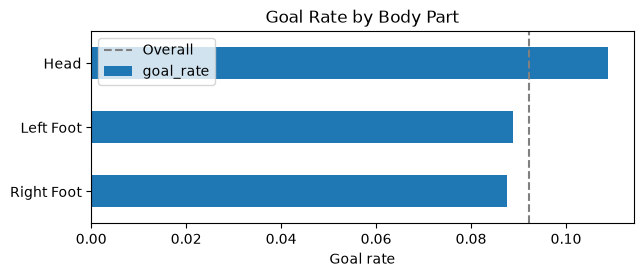

,goal_rate,shots
shot_body_part,,
Right Foot,0.0875,8160
Left Foot,0.088908,4589
Head,0.10882,2619


In [15]:
# By body part
goal_rate_bar(shots, "shot_body_part", "Goal Rate by Body Part")

My thoughts here...

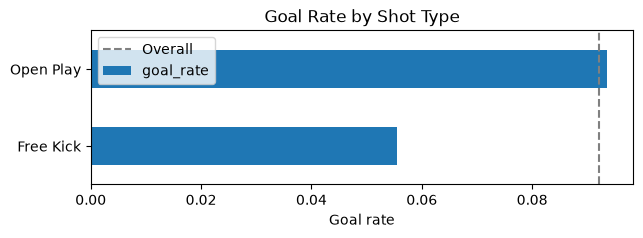

,goal_rate,shots
shot_type,,
Free Kick,0.055465,613
Open Play,0.09363,14803


In [16]:
# By shot type
goal_rate_bar(shots, "shot_type", "Goal Rate by Shot Type")

My thoughts here...

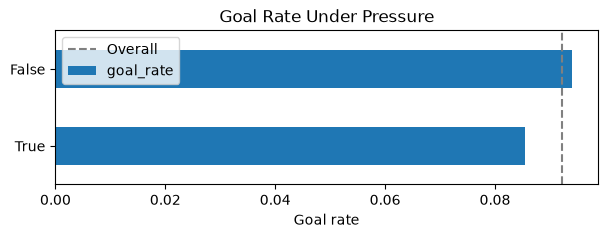

,goal_rate,shots
under_pressure,,
True,0.08542,3395
False,0.094031,12028


In [17]:
# Under pressure
goal_rate_bar(shots, "under_pressure", "Goal Rate Under Pressure")

My thoughts here...

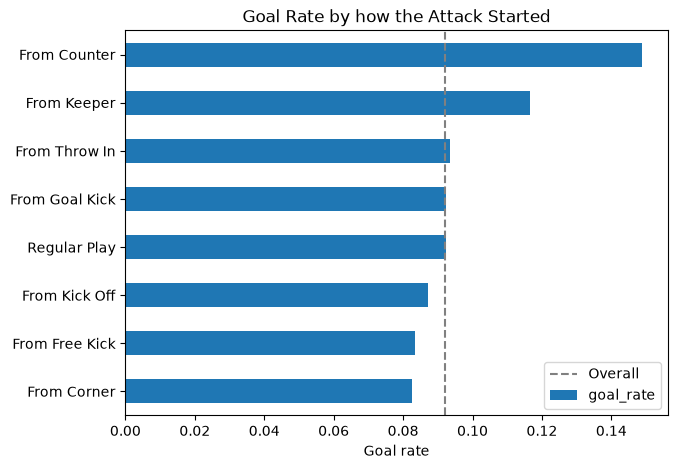

,goal_rate,shots
play_pattern,,
From Corner,0.082597,2603
From Free Kick,0.08342,2901
From Kick Off,0.087209,172
Regular Play,0.09236,5262
From Goal Kick,0.09245,649
From Throw In,0.093412,2869
From Keeper,0.116466,249
From Counter,0.148844,692


In [18]:
# By play pattern/attack setup
goal_rate_bar(shots, "play_pattern", "Goal Rate by how the Attack Started")

My thoughts here...

# Creating the Shot Map

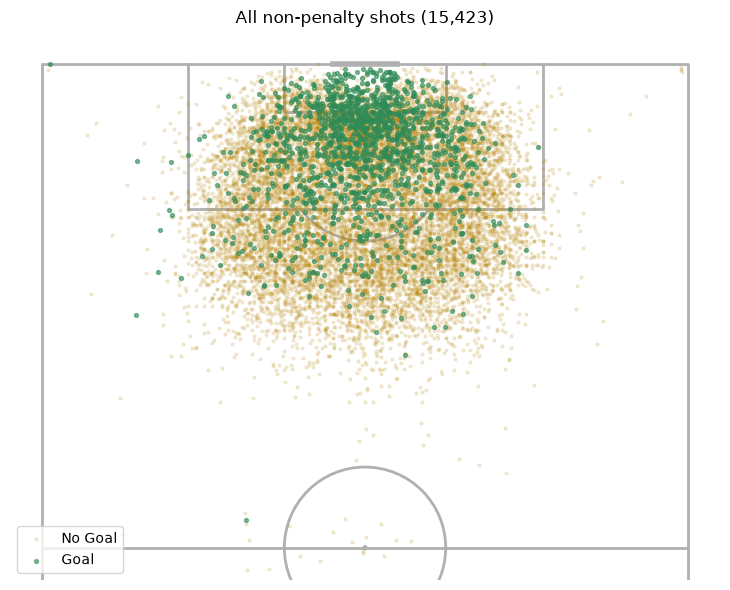

In [28]:
from mplsoccer import VerticalPitch

pitch = VerticalPitch(pitch_type = "statsbomb", half = True)
fig, ax = pitch.draw(figsize = (8, 6))

miss, goal = shots[~shots.is_goal], shots[shots.is_goal]
pitch.scatter(miss.x, miss.y, ax = ax, s = 4, alpha = 0.15, color = "darkgoldenrod", label = "No Goal")
pitch.scatter(goal.x, goal.y, ax = ax, s = 8, alpha = 0.6, color = "seagreen", label = "Goal")
ax.legend(loc = "lower left")
ax.set_title(f"All non-penalty shots ({len(shots):,})")
plt.show()

My thoughts here...